# Customer Segmentation Analysis

## Project objective

This notebook uses **K-Means clustering** to explore groups of customers with similar demographic, household, purchasing, channel, and campaign-response characteristics. The business goal is to generate useful hypotheses for customer-focused marketing and further investigation.

This is an **unsupervised exploratory analysis**: there is no known segment label to predict, and a cluster is not a definitive customer identity or a causal explanation of behavior. The usefulness of any segment depends on appropriate feature preparation, validation, and interpretation.

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE

In [46]:
df = pd.read_csv('data/customer-data.csv')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [47]:
df.shape
#(2240, 29) its indicate that there are 2240 rows and 29 columns in the dataset.

(2240, 29)

## 1. Dataset and data preparation

The source file contains **2,240 customer records and 29 columns**. It combines customer profile fields (such as birth year, education, marital status, and income), household composition, product spending, purchase-channel activity, campaign acceptance indicators, and a response indicator. This makes it possible to explore both customer characteristics and observed behavior.

The columns represent different kinds of information and have very different units. Spending fields are monetary amounts, purchase and household fields are counts, campaign fields are binary indicators, and profile fields include categories. That mix is important: K-Means compares Euclidean distances, so encoding and scaling choices can strongly affect the result.

### Data quality checks

The inspection below checks data types, descriptive statistics, missingness, and the number of distinct values. In the supplied data, `Income` has **24 missing values (about 1.1%)**; the other columns are complete. The raw mean income is approximately **52,247**, while the maximum is **666,666**, so the distribution includes an extreme value that should be investigated before distance-based modeling. `Year_Birth` also includes 1893, a value that merits a plausibility check.

The notebook retains all **2,240 customers** and imputes missing numeric values with the median inside the modeling pipeline, avoiding unnecessary row loss. The data also contains two birth years before 1900 (1893 and 1899). These are treated as implausible for this dataset: age is marked missing for those records and median-imputed for modeling rather than silently deleting the customers. This is an explicit analysis rule, not a verified correction of the source records. Income is strongly right-skewed and includes a maximum of 666,666; robust scaling reduces, but does not eliminate, the influence of extreme values.

In [48]:
df.info() #this function is used to get a concise summary of the DataFrame, including the number of non-null entries, data types, and memory usage.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [49]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [50]:
#checking for missing values in the dataset
for column in df.columns:
    temp = df[column].isnull().sum()
    if temp > 0:
        print(f"{column} has {temp} missing values")

Income has 24 missing values


In [51]:
print(f"Rows retained for analysis: {len(df):,}")
print(f"Missing income values to impute: {df['Income'].isna().sum()}")
print(f"Birth years before 1900 to review: {(df['Year_Birth'] < 1900).sum()}")

Rows retained for analysis: 2,240
Missing income values to impute: 24
Birth years before 1900 to review: 2


In [52]:
df.nunique() #this function is used to get the number of unique values in each column of the DataFrame.

ID                     2240
Year_Birth               59
Education                 5
Marital_Status            8
Income                 1974
Kidhome                   3
Teenhome                  3
Dt_Customer             663
Recency                 100
MntWines                776
MntFruits               158
MntMeatProducts         558
MntFishProducts         182
MntSweetProducts        177
MntGoldProds            213
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
AcceptedCmp2              2
Complain                  2
Z_CostContact             1
Z_Revenue                 1
Response                  2
dtype: int64

In [53]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")

In [54]:
df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"], inplace=True)

## 2. Exploratory data analysis

The visualizations summarize the two categorical profile fields and compare campaign response counts across their categories. In this dataset, **Education** is led by Graduation (1,127 customers, about 50%), followed by PhD (486, about 22%) and Master (370, about 17%). The largest marital-status groups are Married (864, about 39%) and Together (580, about 26%); smaller values such as Alone, Absurd, and YOLO should be treated cautiously because they represent very few records.

The response charts show the **within-category response percentage**, rather than raw counts, so categories of different sizes can be compared more fairly. Small categories still have less reliable estimates, and the charts describe association in this dataset rather than explaining why customers responded.

### Feature preparation and correlation

The registration date is parsed as a date and represented in the model by **tenure in days relative to the latest registration date in this dataset**. The customer `ID` and two constant-valued fields are excluded. The source birth year is converted to age relative to that same dataset reference year; birth years before 1900 are flagged as implausible and their derived ages are median-imputed during preprocessing.

Education and marital status are nominal categories, so the clustering pipeline uses **one-hot encoding** instead of assigning arbitrary integer ranks. Numeric features are median-imputed and robust-scaled. Campaign acceptance fields and `Response` are excluded from clustering and retained for post-cluster profiling, which avoids using the response being analyzed to define the segments. The correlation plot uses only original numeric columns and excludes campaign outcomes.

In [55]:
floats, objects = [], []
for col in df.columns:
    if df[col].dtype == object:
        objects.append(col)
    elif df[col].dtype == float:
        floats.append(col)

print(objects)
print(floats)

['Education', 'Marital_Status']
['Income']


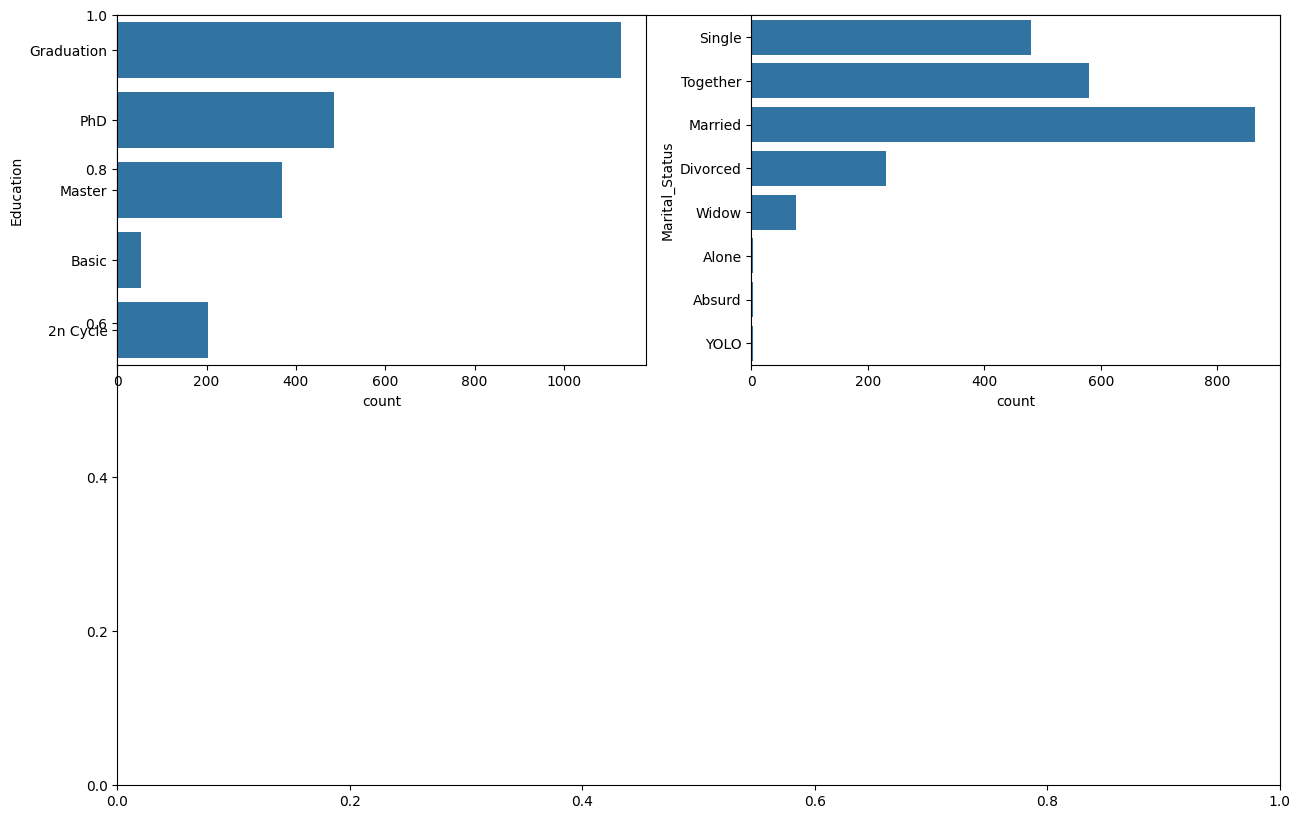

In [56]:
plt.subplots(figsize=(15, 10))
for i, col in enumerate(objects):
    plt.subplot(2, 2, i + 1)
    sb.countplot(df[col])
plt.show()

In [57]:
df['Marital_Status'].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

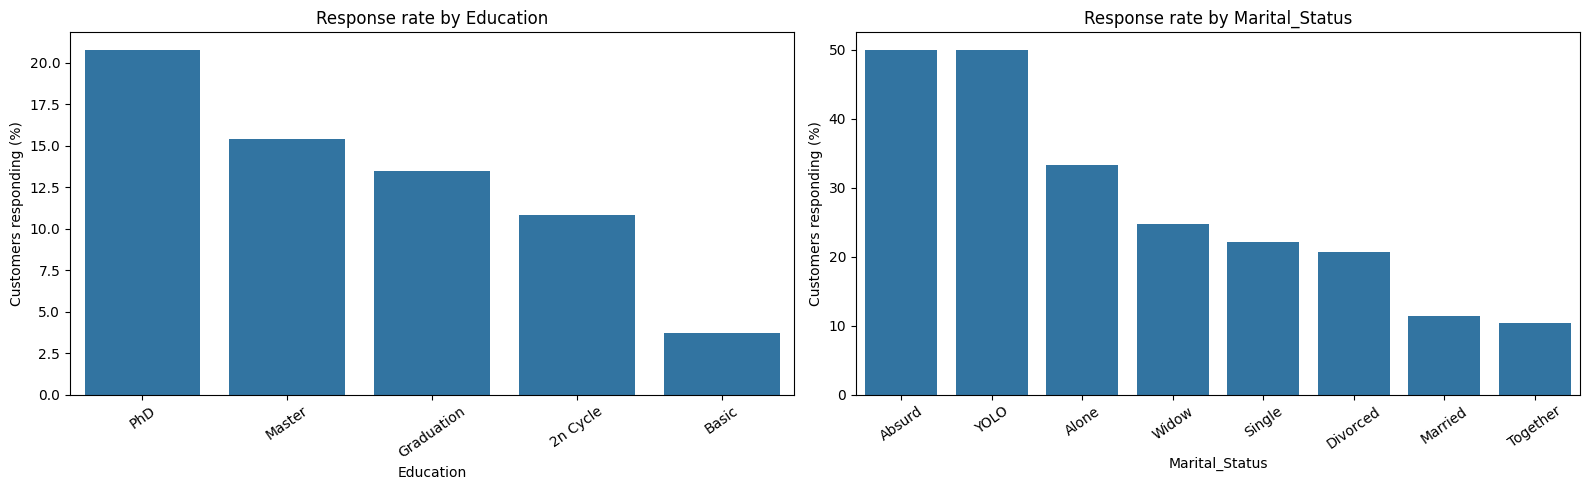

In [58]:
fig, axes = plt.subplots(1, len(objects), figsize=(16, 5))
for ax, col in zip(axes, objects):
    response_rate = df.groupby(col, observed=False)["Response"].mean().mul(100).sort_values(ascending=False)
    sb.barplot(x=response_rate.index, y=response_rate.values, ax=ax)
    ax.set_title(f"Response rate by {col}")
    ax.set_ylabel("Customers responding (%)")
    ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

In [59]:
# Keep nominal categories as text; one-hot encoding is applied in the clustering pipeline.

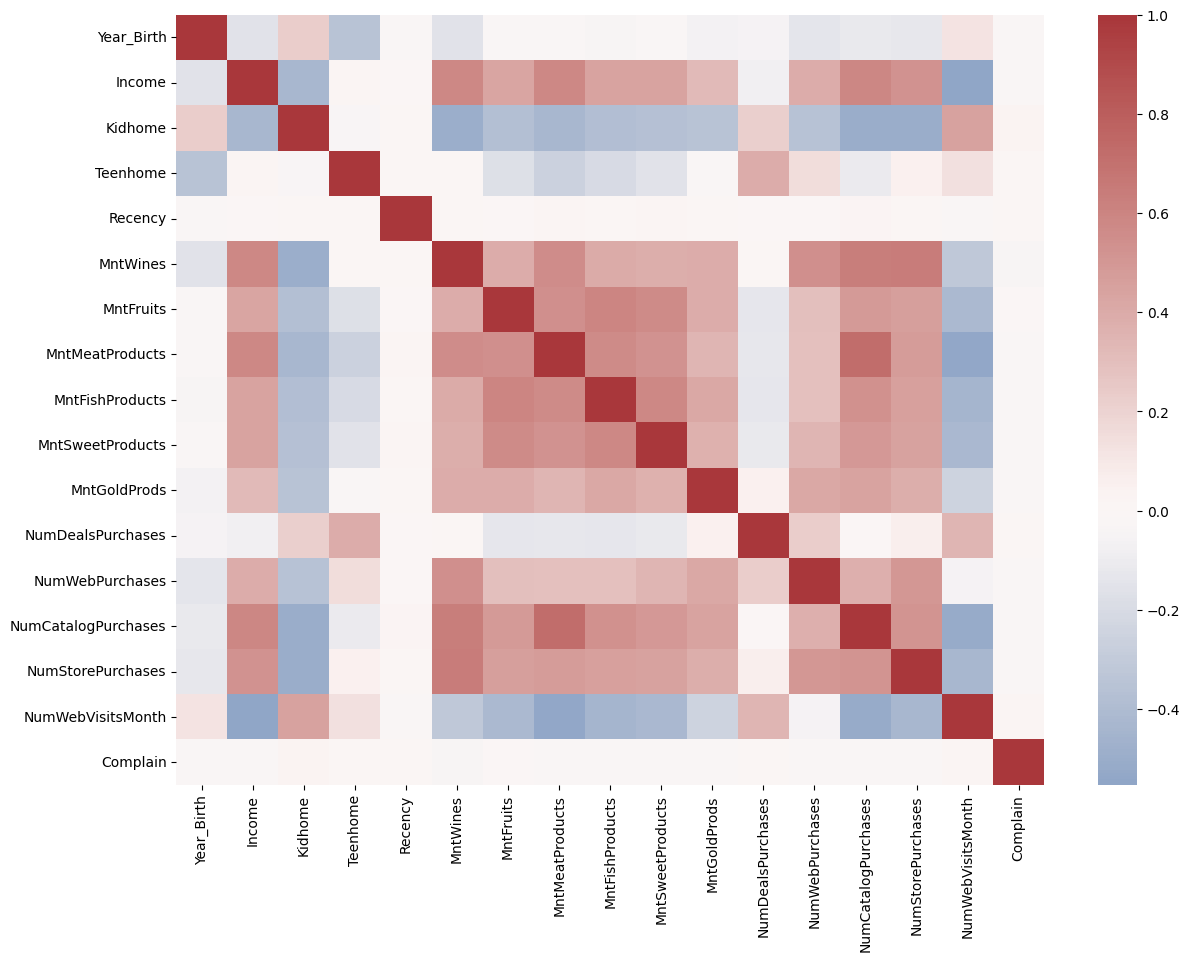

In [60]:
numeric_df = df.select_dtypes(include=np.number).drop(columns=["Response", "AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"], errors="ignore")
plt.figure(figsize=(14, 10))
sb.heatmap(numeric_df.corr(), cmap="vlag", center=0, annot=False)
plt.show()

## 3. Feature scaling and 2D exploration

A `ColumnTransformer` now creates a single prepared feature matrix used by both t-SNE and K-Means. Numeric fields are median-imputed and transformed with `RobustScaler`, nominal categories are imputed and one-hot encoded, and the binary complaint indicator is passed through. Robust scaling is less sensitive to extreme values than standard scaling, although it cannot make a bad source value correct. Campaign outcomes are deliberately held out for later profiling.

The t-SNE scatterplot is intended as a visual summary in two dimensions. It is an exploratory projection, not a clustering algorithm or a proof that naturally distinct groups exist. Its geometry can change with preprocessing and t-SNE settings, so assess it only after using an appropriate feature matrix and do not infer business meaning from the axes.

In [61]:
reference_date = df["Dt_Customer"].max()
df["TenureDays"] = (reference_date - df["Dt_Customer"]).dt.days
df["Age"] = reference_date.year - df["Year_Birth"]

# Treat birth years before 1900 as implausible for this dataset and impute age later.
df.loc[df["Year_Birth"] < 1900, "Age"] = np.nan

numeric_features = [
    "Age", "Income", "Kidhome", "Teenhome", "Recency",
    "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts",
    "MntSweetProducts", "MntGoldProds", "NumDealsPurchases",
    "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
    "NumWebVisitsMonth", "TenureDays"
]
categorical_features = ["Education", "Marital_Status"]
binary_features = ["Complain"]
model_features = numeric_features + categorical_features + binary_features

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
    ("binary", "passthrough", binary_features)
])

transformed = preprocessor.fit_transform(df[model_features])
data = transformed.toarray() if hasattr(transformed, "toarray") else transformed
print(f"Clustering matrix: {data.shape[0]:,} customers x {data.shape[1]} prepared features")

Clustering matrix: 2,240 customers x 31 prepared features


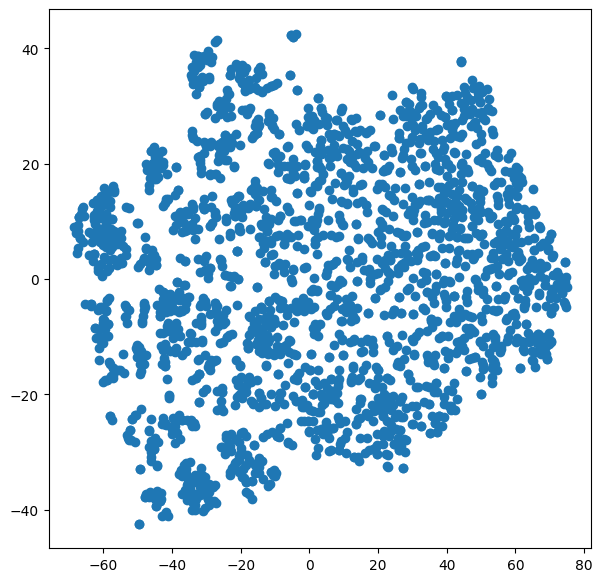

In [62]:
model = TSNE(n_components=2, random_state=0, init="pca", learning_rate="auto")
tsne_data = model.fit_transform(data)
plt.figure(figsize=(7, 7))
plt.scatter(tsne_data[:, 0], tsne_data[:, 1])
plt.show()

## 4. Selecting a cluster count

The elbow method compares K-Means **inertia** (the within-cluster sum of squared distances) across candidate values of *k*. Inertia always decreases as more clusters are added, so the useful signal is a clear bend where further clusters yield diminishing improvement - not simply the lowest plotted value.

The notebook compares *k* from 2 through 8 using both inertia and silhouette score on the prepared feature matrix. In this dataset run, **k = 2 has the highest silhouette score (about 0.331)** among those candidates; scores for 3 to 8 clusters are lower. The final model therefore uses two clusters for this iteration. Silhouette is a diagnostic rather than proof of a business-optimal segmentation, and the result should also be checked for stability and usefulness.

In [63]:
cluster_counts = list(range(2, 9))
inertia_values = []
silhouette_values = []
cluster_size_profiles = []

for n_clusters in cluster_counts:
    candidate_model = KMeans(
        init="k-means++", n_clusters=n_clusters, max_iter=500,
        random_state=22, n_init=20
    )
    candidate_labels = candidate_model.fit_predict(data)
    inertia_values.append(candidate_model.inertia_)
    silhouette_values.append(silhouette_score(data, candidate_labels))
    cluster_size_profiles.append(pd.Series(candidate_labels).value_counts().sort_index().tolist())

cluster_metrics = pd.DataFrame({
    "Clusters": cluster_counts,
    "Inertia": inertia_values,
    "Silhouette": silhouette_values,
    "Cluster sizes": cluster_size_profiles
})
cluster_metrics

,Clusters,Inertia,Silhouette,Cluster sizes
0,2,21537.675662,0.330991,"[1506, 734]"
1,3,19284.776172,0.195255,"[568, 1032, 640]"
2,4,17945.516983,0.184451,"[1005, 263, 458, 514]"
3,5,17198.748124,0.185672,"[410, 1003, 510, 152, 165]"
4,6,16510.043044,0.176310,"[355, 983, 448, 170, 133, 151]"
5,7,15880.064654,0.176253,"[237, 142, 967, 168, 228, 353, 145]"
6,8,15392.299606,0.097501,"[326, 481, 224, 146, 211, 550, 157, 145]"


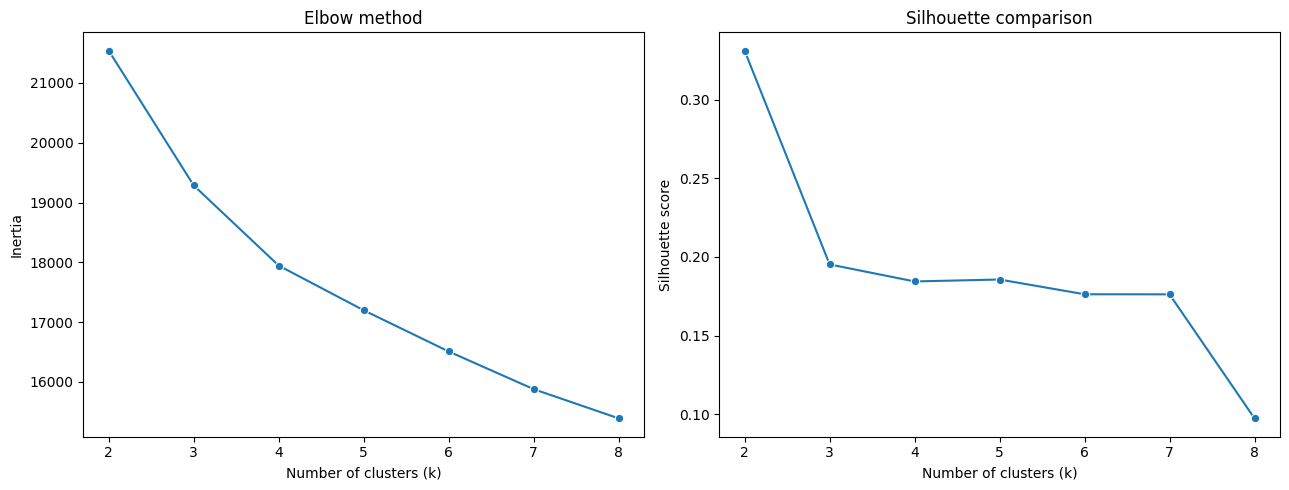

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sb.lineplot(x=cluster_counts, y=inertia_values, marker="o", ax=axes[0])
axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia")
sb.lineplot(x=cluster_counts, y=silhouette_values, marker="o", ax=axes[1])
axes[1].set(title="Silhouette comparison", xlabel="Number of clusters (k)", ylabel="Silhouette score")
plt.tight_layout()
plt.show()

## 5. Cluster results and interpretation

The final cell assigns each customer to the selected K-Means cluster, colors the t-SNE projection by that label, and reports original-scale customer profiles and campaign-response percentages. A label is only an identifier: cluster 0 is not inherently better, more valuable, or more important than cluster 1. The profiles are descriptive, and the t-SNE plot is an exploratory projection rather than independent validation.

In [65]:
selected_k = cluster_counts[int(np.argmax(silhouette_values))]
model = KMeans(
    init="k-means++", n_clusters=selected_k, max_iter=500,
    random_state=22, n_init=20
)
segments = model.fit_predict(data)
print(f"Selected k by highest silhouette score: {selected_k}")
print(f"Silhouette score: {max(silhouette_values):.3f}")

Selected k by highest silhouette score: 2
Silhouette score: 0.331


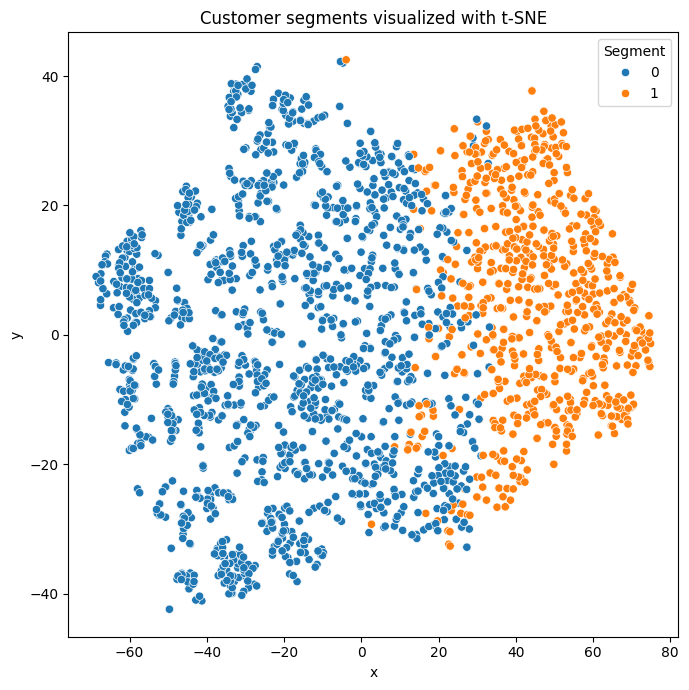

,Customers,Mean_Age,Mean_Income,Mean_Wine_Spend,Mean_Meat_Spend,Mean_Web_Purchases,Mean_Catalog_Purchases,Mean_Store_Purchases,Share_Percent
Segment,,,,,,,,,
0,1506,44.5,41599.8,167.6,49.3,3.4,1.2,4.5,67.2
1,734,46.3,74054.8,583.6,408.4,5.6,5.6,8.5,32.8


,AcceptedCmp1_Rate_Percent,AcceptedCmp2_Rate_Percent,AcceptedCmp3_Rate_Percent,AcceptedCmp4_Rate_Percent,AcceptedCmp5_Rate_Percent,Response_Rate_Percent
Segment,,,,,,
0,1.5,1.0,7.1,6.2,1.1,10.6
1,16.6,2.0,7.6,10.1,20.0,23.8


In [66]:
plt.figure(figsize=(7, 7))

df_tsne = pd.DataFrame({'x': tsne_data[:, 0], 'y': tsne_data[:, 1], 'segment': segments})

sb.scatterplot(x="x", y="y", hue="segment", data=df_tsne, palette="tab10")
plt.title("Customer segments visualized with t-SNE")
plt.legend(title="Segment")
plt.tight_layout()
plt.show()

clustered = df.copy()
clustered["Segment"] = segments
segment_profile = clustered.groupby("Segment").agg(
    Customers=("Segment", "size"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Income", "mean"),
    Mean_Wine_Spend=("MntWines", "mean"),
    Mean_Meat_Spend=("MntMeatProducts", "mean"),
    Mean_Web_Purchases=("NumWebPurchases", "mean"),
    Mean_Catalog_Purchases=("NumCatalogPurchases", "mean"),
    Mean_Store_Purchases=("NumStorePurchases", "mean")
).round(1)
segment_profile["Share_Percent"] = (segment_profile["Customers"] / len(clustered) * 100).round(1)
display(segment_profile)

campaign_columns = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]
campaign_rates = clustered.groupby("Segment")[campaign_columns].mean().mul(100).round(1)
display(campaign_rates.rename(columns=lambda column: f"{column}_Rate_Percent"))

### Results and interpretation

With the revised preprocessing and fixed random seed, the two-cluster solution contains **1,506 customers in Segment 0 (67.2%)** and **734 in Segment 1 (32.8%)**. Segment labels are arbitrary; the table below summarizes the original-scale means from this run.

| Segment | Customers | Share | Mean income | Mean wine spend | Mean meat spend | Mean web purchases | Response rate |
|:--|--:|--:|--:|--:|--:|--:|--:|
| 0 | 1,506 | 67.2% | 41,600 | 168 | 49 | 3.4 | 10.6% |
| 1 | 734 | 32.8% | 74,055 | 584 | 408 | 5.6 | 23.8% |

In this run, Segment 1 has higher average income, product spending, web purchasing, and observed campaign response. This is a descriptive association, not evidence that the segment assignment causes campaign response. Campaign response was excluded from the features used to create the groups and is shown afterward for profiling.

### Conclusion and remaining validation

The workflow now excludes identifiers, imputes missing values, flags implausible birth years, uses tenure instead of raw date components, one-hot encodes nominal categories, robust-scales numeric fields, and passes the same prepared features to t-SNE and K-Means. Response comparisons use rates rather than counts, and cluster count is compared with silhouette scores.

The analysis remains exploratory. The silhouette score for two groups is moderate, and the result has not been tested across resampled datasets or independently confirmed as useful for a business decision. Before using these segments operationally, assess stability, review the data-quality rules with a domain expert, and test whether the profiles support a specific marketing action. **Preprocessing choices define the distances K-Means sees, and those distances define the segments.**